Status: Optimal
Total Profit: $7,066,033.84

Production Plan (Total Units):
     Widgets  Gadgets   Flugels
1   69.99998  320.000  140.0000
2  125.00000  243.035  356.4810
3  185.00000  231.965  301.9376
4  189.99960  245.000  279.1160
5  200.00050  240.000  274.6899

Inventory Levels (Total Units):
   Widgets   Gadgets  Flugels
1      0.0  120.0000      0.0
2      0.0   63.0354      0.0
3      0.0    0.0000      0.0
4      0.0    0.0000      0.0
5      0.0    0.0000      0.0

Regular Labor Utilization (Hours):
            A            B
1  2499.99980  1952.547378
2  1725.54850  3799.997400
3  2500.00305  3800.001210
4  2499.99970  3799.998900
5  2500.00025  3800.005100

Overtime Labor Utilization (Hours):
     A           B
1  0.0     0.00000
2  0.0  1116.20120
3  0.0   266.90376
4  0.0   159.14840
5  0.0   169.22794

Raw Material 1 Usage (Pounds):
         A        B
1  74005.5  36672.7
2  55898.1  84101.9
3  70772.1  69227.9
4  71880.2  68119.8
5  71455.2  68544.8

Raw Material 2 Us

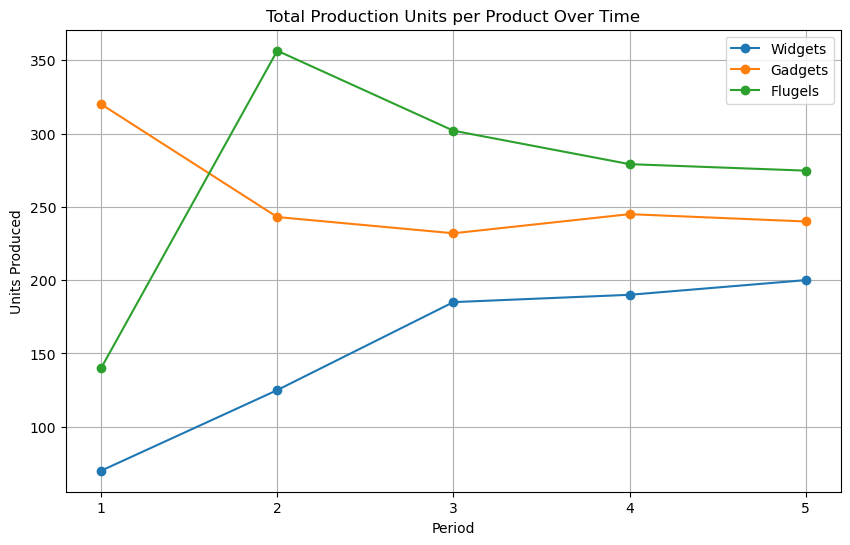

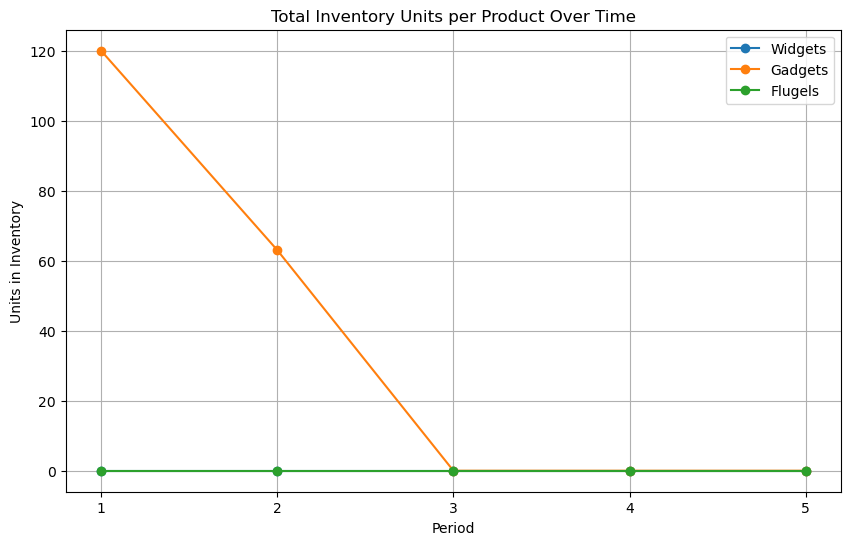

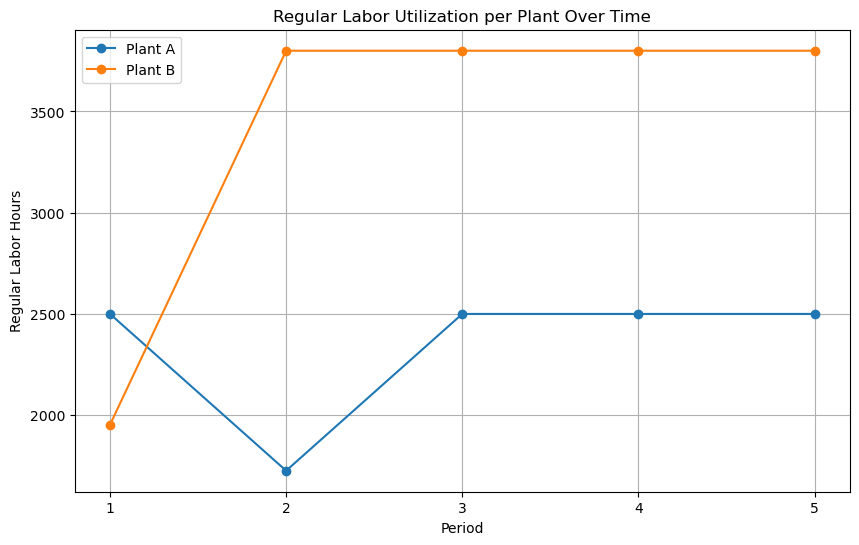

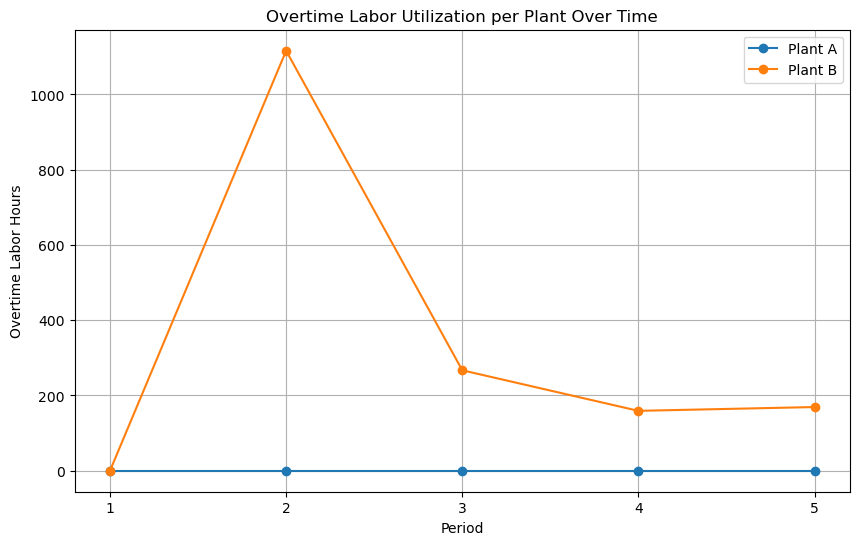

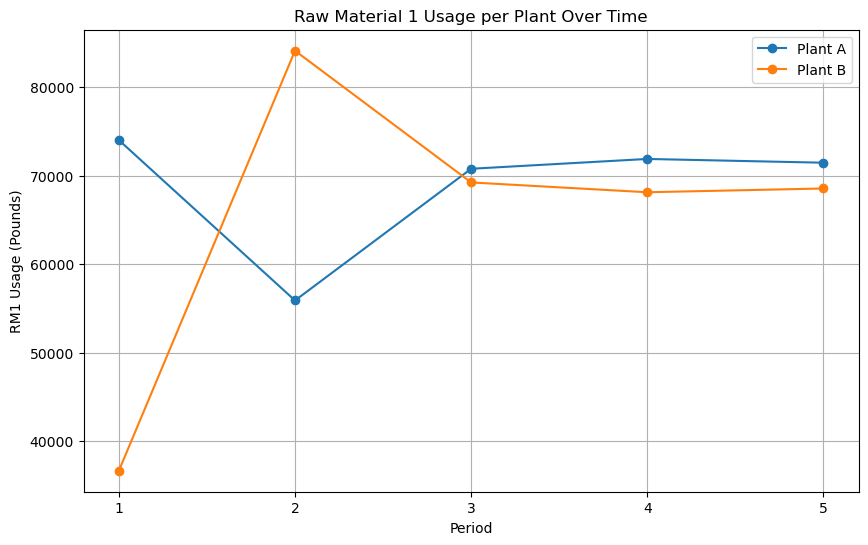

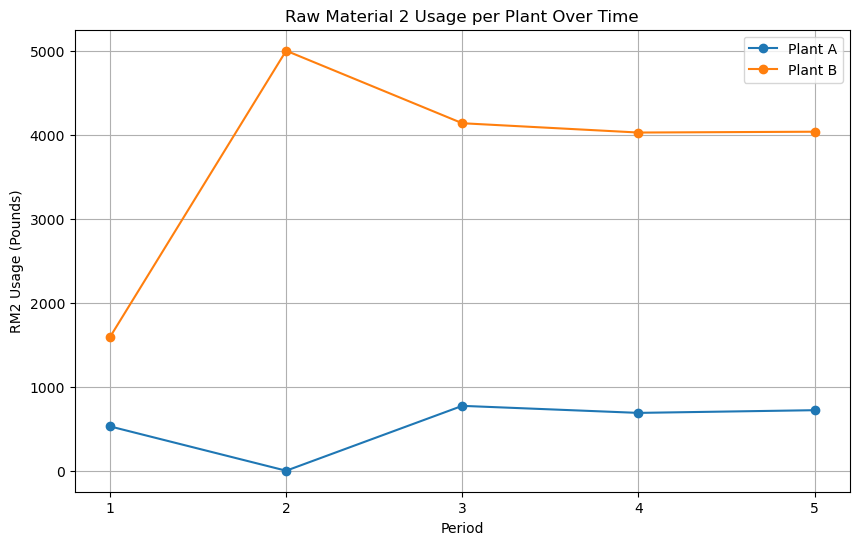

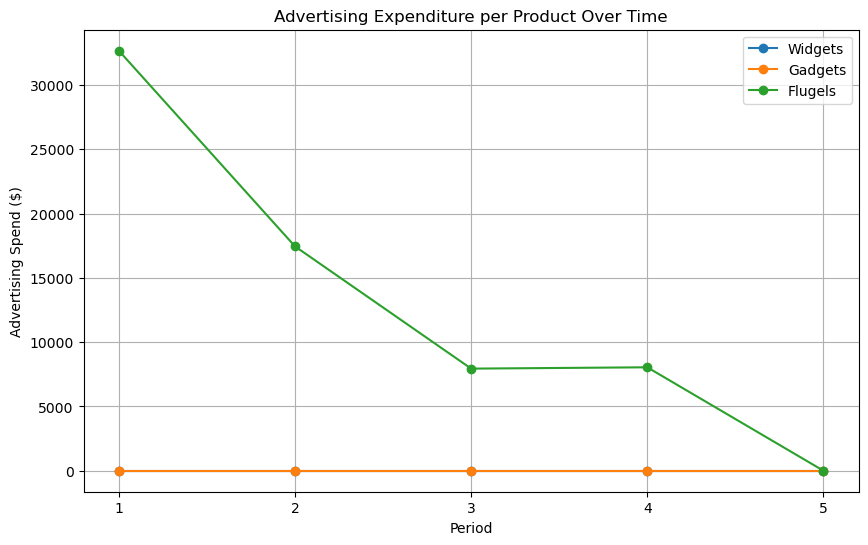

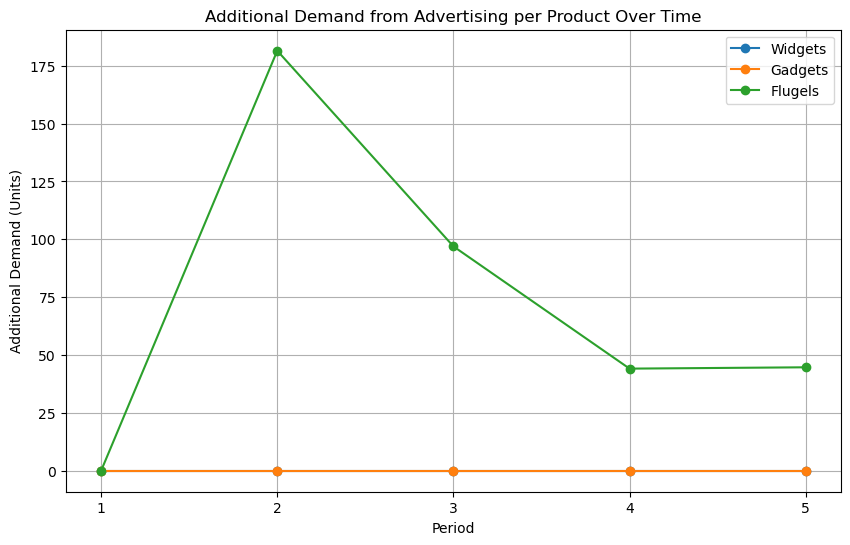


Sensitivity analysis report has been generated in 'C:\Users\qjkru\OneDrive\Desktop\5. MSDS NU Classes\1. Classes\D. 2024 Q1 - Fall\2. MSDS 460 SEC55 Decision Analytics\D. Project\sensitivity.txt'.


In [8]:
import pulp
import pandas as pd
import matplotlib.pyplot as plt
import os

# Define sets
products = ['Widgets', 'Gadgets', 'Flugels']
plants = ['A', 'B']
periods = [1, 2, 3, 4, 5]
periods0 = [0] + periods  # Include period 0 for inventory initialization

# Parameters
# Selling prices
prices = {'Widgets': 2490, 'Gadgets': 1990, 'Flugels': 2970}

# Base demand
base_demand = {
    ('Widgets', 1): 70, ('Widgets', 2): 125, ('Widgets', 3): 185, ('Widgets', 4): 190, ('Widgets', 5): 200,
    ('Gadgets', 1): 200, ('Gadgets', 2): 300, ('Gadgets', 3): 295, ('Gadgets', 4): 245, ('Gadgets', 5): 240,
    ('Flugels', 1): 140, ('Flugels', 2): 175, ('Flugels', 3): 205, ('Flugels', 4): 235, ('Flugels', 5): 230
}

# Advertising costs per unit of additional demand
ad_cost = {'Widgets': 160, 'Gadgets': 120, 'Flugels': 180}

# Production requirements
rm1 = {
    ('Widgets', 'A'): 194, ('Gadgets', 'A'): 230, ('Flugels', 'A'): 178,
    ('Widgets', 'B'): 188, ('Gadgets', 'B'): 225, ('Flugels', 'B'): 170
}

rm2 = {
    ('Widgets', 'A'): 8.6,  ('Gadgets', 'A'): 0,    ('Flugels', 'A'): 11.6,
    ('Widgets', 'B'): 9.2,  ('Gadgets', 'B'): 0,    ('Flugels', 'B'): 10.8
}

labor_hours = {
    ('Widgets', 'A'): 9.5,  ('Gadgets', 'A'): 7.1,  ('Flugels', 'A'): 11.1,
    ('Widgets', 'B'): 9.1,  ('Gadgets', 'B'): 7.8,  ('Flugels', 'B'): 10.6
}

# Labor costs
regular_labor_cost = {}
overtime_labor_cost = {}
for s in plants:
    for t in periods:
        if t <= 2:
            regular_labor_cost[(s, t)] = 11
            overtime_labor_cost[(s, t)] = 16.5
        else:
            if s == 'A':
                regular_labor_cost[(s, t)] = 11 * 1.05  # 5% increase
                overtime_labor_cost[(s, t)] = 16.5 * 1.05
            elif s == 'B':
                regular_labor_cost[(s, t)] = 11 * 1.10  # 10% increase
                overtime_labor_cost[(s, t)] = 16.5 * 1.10

# Raw material costs
rm_cost = {
    ('A', 'RM1'): 1.25, ('A', 'RM2'): 2.65,
    ('B', 'RM1'): 1.45, ('B', 'RM2'): 2.90
}

# Inventory holding costs
inv_cost = {
    ('Widgets', 'A'): 7.50, ('Gadgets', 'A'): 5.50, ('Flugels', 'A'): 6.50,
    ('Widgets', 'B'): 7.80, ('Gadgets', 'B'): 5.70, ('Flugels', 'B'): 7.00
}

# Transportation costs
trans_cost = {
    ('Widgets', 'A'): 6.30, ('Gadgets', 'A'): 4.60, ('Flugels', 'A'): 5.50,
    ('Widgets', 'B'): 6.50, ('Gadgets', 'B'): 5.00, ('Flugels', 'B'): 5.70
}

# Inventory capacities
inv_cap = {'A': 70, 'B': 50}

# Labor availability
regular_time_limit = {'A': 2500, 'B': 3800}

# Raw material availability per period
rm1_available = 140000  # pounds (70 tons)
rm2_available = 5000    # pounds (2.5 tons)

# Advertising budget
adv_budget = 70000

# Initialize the problem
prob = pulp.LpProblem("NU_Industries_Profit_Maximization", pulp.LpMaximize)

# Decision Variables
x = pulp.LpVariable.dicts("RegProd", ((p, s, t) for p in products for s in plants for t in periods), lowBound=0)
y = pulp.LpVariable.dicts("OverProd", ((p, s, t) for p in products for s in plants for t in periods), lowBound=0)
inv = pulp.LpVariable.dicts("Inventory", ((p, s, t) for p in products for s in plants for t in periods0), lowBound=0)
R1 = pulp.LpVariable.dicts("RM1", ((s, t) for s in plants for t in periods), lowBound=0)
R2 = pulp.LpVariable.dicts("RM2", ((s, t) for s in plants for t in periods), lowBound=0)
Adv = pulp.LpVariable.dicts("Advertising", ((p, t) for p in products for t in periods), lowBound=0)
D = {}  # Additional demand due to advertising
ship = pulp.LpVariable.dicts("Shipment", ((p, s, t) for p in products for s in plants for t in periods), lowBound=0)

# Parameters for additional demand calculation
for p in products:
    for t in periods:
        D[(p, t)] = pulp.LpVariable(f"AddDemand_{p}_{t}", lowBound=0)

# Objective Function Components
revenue = pulp.lpSum([
    prices[p] * (base_demand[(p, t)] + D[(p, t)])
    for p in products for t in periods
])

labor_cost = pulp.lpSum([
    labor_hours[(p, s)] * (
        x[(p, s, t)] * regular_labor_cost[(s, t)] +
        y[(p, s, t)] * overtime_labor_cost[(s, t)]
    )
    for p in products for s in plants for t in periods
])

rm_cost_total = pulp.lpSum([
    R1[(s, t)] * rm_cost[(s, 'RM1')] +
    R2[(s, t)] * rm_cost[(s, 'RM2')]
    for s in plants for t in periods
])

inv_cost_total = pulp.lpSum([
    inv[(p, s, t)] * inv_cost[(p, s)]
    for p in products for s in plants for t in periods
])

trans_cost_total = pulp.lpSum([
    ship[(p, s, t)] * trans_cost[(p, s)]
    for p in products for s in plants for t in periods
])

adv_cost_total = pulp.lpSum([
    Adv[(p, t)]
    for p in products for t in periods
])

# Set Objective
prob += revenue - (labor_cost + rm_cost_total + inv_cost_total + trans_cost_total + adv_cost_total), "Total Profit"

# Constraints
# Initial Inventory
for p in products:
    for s in plants:
        prob += inv[(p, s, 0)] == 0, f"InitialInv_{p}_{s}"

# Demand Satisfaction
for p in products:
    for t in periods:
        prob += pulp.lpSum([
            ship[(p, s, t)]
            for s in plants
        ]) >= base_demand[(p, t)] + D[(p, t)], f"Demand_{p}_{t}"

# Inventory Balance
for p in products:
    for s in plants:
        for t in periods:
            prob += inv[(p, s, t)] == inv[(p, s, t-1)] + x[(p, s, t)] + y[(p, s, t)] - ship[(p, s, t)], f"InvBalance_{p}_{s}_{t}"

# Final Inventory Zero
for p in products:
    for s in plants:
        prob += inv[(p, s, periods[-1])] == 0, f"FinalInv_{p}_{s}"

# Inventory Capacity
for s in plants:
    for t in periods:
        prob += pulp.lpSum([inv[(p, s, t)] for p in products]) <= inv_cap[s], f"InvCap_{s}_{t}"

# Labor Availability
for s in plants:
    for t in periods:
        prob += pulp.lpSum([
            labor_hours[(p, s)] * x[(p, s, t)]
            for p in products
        ]) <= regular_time_limit[s], f"LaborReg_{s}_{t}"

# Raw Material Usage and Purchase
for s in plants:
    for t in periods:
        prob += R1[(s, t)] == pulp.lpSum([
            rm1[(p, s)] * (x[(p, s, t)] + y[(p, s, t)])
            for p in products
        ]), f"RM1Use_{s}_{t}"
        prob += R2[(s, t)] == pulp.lpSum([
            rm2[(p, s)] * (x[(p, s, t)] + y[(p, s, t)])
            for p in products
        ]), f"RM2Use_{s}_{t}"

# Raw Material Availability
for t in periods:
    prob += pulp.lpSum([R1[(s, t)] for s in plants]) <= rm1_available, f"RM1Avail_{t}"
    prob += pulp.lpSum([R2[(s, t)] for s in plants]) <= rm2_available, f"RM2Avail_{t}"

# Advertising Budget
prob += pulp.lpSum([Adv[(p, t)] for p in products for t in periods]) <= adv_budget, "AdvBudget"

# Additional Demand from Advertising (Corrected Constraint)
for p in products:
    for t in periods:
        if t == 1:
            prob += D[(p, t)] == 0, f"AddDemandInit_{p}_{t}"
        else:
            prob += Adv[(p, t - 1)] == ad_cost[p] * D[(p, t)], f"AddDemand_{p}_{t}"

# Solve the problem using GLPK and output sensitivity analysis to the specified path

# Define the desired directory
sensitivity_dir = r"C:\Users\qjkru\OneDrive\Desktop\5. MSDS NU Classes\1. Classes\D. 2024 Q1 - Fall\2. MSDS 460 SEC55 Decision Analytics\D. Project"

# Define the sensitivity report file path
sensitivity_report_path = os.path.join(sensitivity_dir, 'sensitivity.txt')

prob.solve(pulp.GLPK(msg=False, options=['--ranges', sensitivity_report_path]))

# Output the results
print(f"Status: {pulp.LpStatus[prob.status]}")
print(f"Total Profit: ${pulp.value(prob.objective):,.2f}")

# Initialize DataFrames for production, inventory, labor utilization, overtime, raw materials, advertising
prod_df = pd.DataFrame(index=periods, columns=products)
inv_df = pd.DataFrame(index=periods, columns=products)
labor_df = pd.DataFrame(index=periods, columns=plants)
overtime_df = pd.DataFrame(index=periods, columns=plants)
rm1_df = pd.DataFrame(index=periods, columns=plants)
rm2_df = pd.DataFrame(index=periods, columns=plants)
adv_df = pd.DataFrame(index=periods, columns=products)
add_demand_df = pd.DataFrame(index=periods, columns=products)

# Populate DataFrames with production data
for t in periods:
    for p in products:
        total_prod = 0
        for s in plants:
            reg_prod = x[(p, s, t)].varValue
            over_prod = y[(p, s, t)].varValue
            total_prod += reg_prod + over_prod
        prod_df.at[t, p] = total_prod

# Populate DataFrames with inventory data
for t in periods:
    for p in products:
        total_inv = 0
        for s in plants:
            inv_level = inv[(p, s, t)].varValue
            total_inv += inv_level
        inv_df.at[t, p] = total_inv

# Calculate labor utilization and overtime
for t in periods:
    for s in plants:
        reg_labor = sum([
            labor_hours[(p, s)] * x[(p, s, t)].varValue
            for p in products
        ])
        over_labor = sum([
            labor_hours[(p, s)] * y[(p, s, t)].varValue
            for p in products
        ])
        labor_df.at[t, s] = reg_labor
        overtime_df.at[t, s] = over_labor

# Raw material usage
for t in periods:
    for s in plants:
        rm1_usage = R1[(s, t)].varValue
        rm2_usage = R2[(s, t)].varValue
        rm1_df.at[t, s] = rm1_usage
        rm2_df.at[t, s] = rm2_usage

# Advertising expenditure and additional demand
for t in periods:
    for p in products:
        adv_spent = Adv[(p, t)].varValue
        additional_demand = D[(p, t)].varValue
        adv_df.at[t, p] = adv_spent
        add_demand_df.at[t, p] = additional_demand

# Convert data to numeric type
prod_df = prod_df.astype(float)
inv_df = inv_df.astype(float)
labor_df = labor_df.astype(float)
overtime_df = overtime_df.astype(float)
rm1_df = rm1_df.astype(float)
rm2_df = rm2_df.astype(float)
adv_df = adv_df.astype(float)
add_demand_df = add_demand_df.astype(float)

# Display production plan
print("\nProduction Plan (Total Units):")
print(prod_df)

# Display inventory levels
print("\nInventory Levels (Total Units):")
print(inv_df)

# Display labor utilization
print("\nRegular Labor Utilization (Hours):")
print(labor_df)

print("\nOvertime Labor Utilization (Hours):")
print(overtime_df)

# Display raw material usage
print("\nRaw Material 1 Usage (Pounds):")
print(rm1_df)

print("\nRaw Material 2 Usage (Pounds):")
print(rm2_df)

# Display advertising expenditure
print("\nAdvertising Expenditure ($):")
print(adv_df)

# Display additional demand due to advertising
print("\nAdditional Demand from Advertising (Units):")
print(add_demand_df)

# Plot production over periods
plt.figure(figsize=(10, 6))
for p in products:
    plt.plot(periods, prod_df[p], marker='o', label=p)
plt.title('Total Production Units per Product Over Time')
plt.xlabel('Period')
plt.ylabel('Units Produced')
plt.xticks(periods)
plt.legend()
plt.grid(True)
plt.show()

# Plot inventory levels over periods
plt.figure(figsize=(10, 6))
for p in products:
    plt.plot(periods, inv_df[p], marker='o', label=p)
plt.title('Total Inventory Units per Product Over Time')
plt.xlabel('Period')
plt.ylabel('Units in Inventory')
plt.xticks(periods)
plt.legend()
plt.grid(True)
plt.show()

# Plot regular labor utilization over periods
plt.figure(figsize=(10, 6))
for s in plants:
    plt.plot(periods, labor_df[s], marker='o', label=f'Plant {s}')
plt.title('Regular Labor Utilization per Plant Over Time')
plt.xlabel('Period')
plt.ylabel('Regular Labor Hours')
plt.xticks(periods)
plt.legend()
plt.grid(True)
plt.show()

# Plot overtime labor utilization over periods
plt.figure(figsize=(10, 6))
for s in plants:
    plt.plot(periods, overtime_df[s], marker='o', label=f'Plant {s}')
plt.title('Overtime Labor Utilization per Plant Over Time')
plt.xlabel('Period')
plt.ylabel('Overtime Labor Hours')
plt.xticks(periods)
plt.legend()
plt.grid(True)
plt.show()

# Plot raw material 1 usage over periods
plt.figure(figsize=(10, 6))
for s in plants:
    plt.plot(periods, rm1_df[s], marker='o', label=f'Plant {s}')
plt.title('Raw Material 1 Usage per Plant Over Time')
plt.xlabel('Period')
plt.ylabel('RM1 Usage (Pounds)')
plt.xticks(periods)
plt.legend()
plt.grid(True)
plt.show()

# Plot raw material 2 usage over periods
plt.figure(figsize=(10, 6))
for s in plants:
    plt.plot(periods, rm2_df[s], marker='o', label=f'Plant {s}')
plt.title('Raw Material 2 Usage per Plant Over Time')
plt.xlabel('Period')
plt.ylabel('RM2 Usage (Pounds)')
plt.xticks(periods)
plt.legend()
plt.grid(True)
plt.show()

# Plot advertising expenditure over periods
plt.figure(figsize=(10, 6))
for p in products:
    plt.plot(periods, adv_df[p], marker='o', label=p)
plt.title('Advertising Expenditure per Product Over Time')
plt.xlabel('Period')
plt.ylabel('Advertising Spend ($)')
plt.xticks(periods)
plt.legend()
plt.grid(True)
plt.show()

# Plot additional demand due to advertising over periods
plt.figure(figsize=(10, 6))
for p in products:
    plt.plot(periods, add_demand_df[p], marker='o', label=p)
plt.title('Additional Demand from Advertising per Product Over Time')
plt.xlabel('Period')
plt.ylabel('Additional Demand (Units)')
plt.xticks(periods)
plt.legend()
plt.grid(True)
plt.show()

# Inform the user about the sensitivity analysis report
print(f"\nSensitivity analysis report has been generated in '{sensitivity_report_path}'.")
